# 6. Piyasa rejimi ve ertesi gün aralık tahmini

**1) Kümeleme:** Her işlem günü beş özellikle tarif edilir (1 aylık oynaklık, 3 aylık getiri, 200 günlük ortalamaya uzaklık, VIX, genişlik). Özellikler standartlaştırılır ve k-ortalamalar (k=4) ile gruplanır.

**2) Aralık tahmini:** Ertesi günün en yüksek–en düşük farkı, logaritmik HAR modeliyle tahmin edilir. Sınama, ileriye doğru yürüyen pencereyle yapılır (geleceği görmeden).

In [1]:
import sys, sqlite3
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from mi import db, stats as st, events as ev, charts
%matplotlib inline
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
con = db.connect()
prices = pd.read_sql('SELECT * FROM prices', con)
close, volume = st.wide(prices), st.wide(prices, 'volume')
r = st.returns(close)
assets = pd.read_sql('SELECT * FROM assets', con).set_index('code')
print(f'{close.shape[1]} varlık, {close.index[0]:%Y-%m-%d} – {close.index[-1]:%Y-%m-%d}, {len(prices):,} fiyat satırı')

109 varlık, 2021-11-01 – 2026-10-30, 130,652 fiyat satırı


In [2]:
from mi import breadth as br, regime as rg
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
stocks = assets.index[assets.cls == 'hisse'].tolist()
p200 = br.above_ma(close[[c for c in stocks if c in close.columns]], 200)
f = rg.features(close['NDX'], close.get('VIX'), p200)
f.describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
vol21,20.04,8.05,7.13,59.62
ret63,5.80,8.81,-20.73,33.58
dist200,7.76,8.52,-18.68,26.07
vix,18.07,4.65,11.86,52.33
breadth,65.67,15.39,8.79,93.55


## Kaç küme? Dirsek yöntemi ve siluet skoru

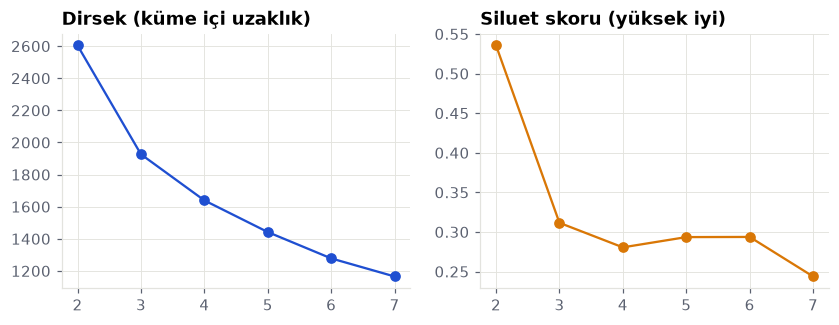

In [3]:
from sklearn.metrics import silhouette_score
X = StandardScaler().fit_transform(f)
ks = range(2, 8)
inertia = [KMeans(k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
sil = [silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X)) for k in ks]
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(list(ks), inertia, marker='o', color=charts.ACC); ax[0].set_title('Dirsek (küme içi uzaklık)')
ax[1].plot(list(ks), sil, marker='o', color='#D97706'); ax[1].set_title('Siluet skoru (yüksek iyi)'); plt.show()

k=4 seçildi: dirseğin kırıldığı yer ve yorumlanabilir dört durum (güçlü yükseliş, kararsız, düzeltme, stres).

In [4]:
R = rg.regimes(f, close['NDX'])
print('Bugün:', R['current'], f"({R['streak']} gündür)")
pd.DataFrame(R['table']).set_index('regime').round(2)

Bugün: Düzeltme (1 gündür)


,share,avg_days,vol21,ret63,dist200,vix,breadth,fwd_mean,fwd_median,fwd_hit,fwd_worst
regime,,,,,,,,,,,
Güçlü yükseliş,36.84,15.56,15.86,13.99,14.49,15.00,76.99,1.09,1.53,65.04,-5.11
Kararsız,41.29,10.14,18.94,3.94,8.71,17.32,66.99,2.08,2.23,71.46,-4.66
Düzeltme,13.83,5.84,23.86,-2.21,-2.03,22.39,52.21,2.49,1.90,60.69,-10.83
Stres,8.05,17.00,38.21,-8.37,-11.10,28.46,30.27,2.82,3.24,63.53,-9.83


## Rejimler arası geçiş olasılıkları (5 işlem günlük adımlarla)

In [5]:
lab = pd.Series([x[1] for x in R['timeline']])
pd.crosstab(lab.shift(), lab, normalize='index').round(2)

col_0,Düzeltme,Güçlü yükseliş,Kararsız,Stres
row_0,,,,
Düzeltme,0.67,0.00,0.22,0.11
Güçlü yükseliş,0.01,0.83,0.15,0.00
Kararsız,0.07,0.14,0.79,0.00
Stres,0.12,0.00,0.06,0.81


## Ertesi gün aralık modeli

In [6]:
hl = pd.read_sql("SELECT date, high, low FROM prices WHERE code='NDX'", con, parse_dates=['date']).set_index('date')
M = rg.range_model(hl['high'], hl['low'], close['NDX'], close.get('VIX'))
pd.DataFrame({'Model': M['model'], 'Dün gibi': M['naive_yesterday'], 'Son ay ortalaması': M['naive_month']}).T.round(3)

,mae,rmse,r2
Model,0.43,0.59,0.17
Dün gibi,0.52,0.74,-0.30
Son ay ortalaması,0.45,0.63,0.05


Katsayılar: {'sabit': -1.836, 'r1': 0.065, 'r5': 0.332, 'r22': 0.074, 'vix': 0.681}
İyileşme: %4, %80 aralık isabeti: %80
Yarın beklenen: 427 puan (219–603)


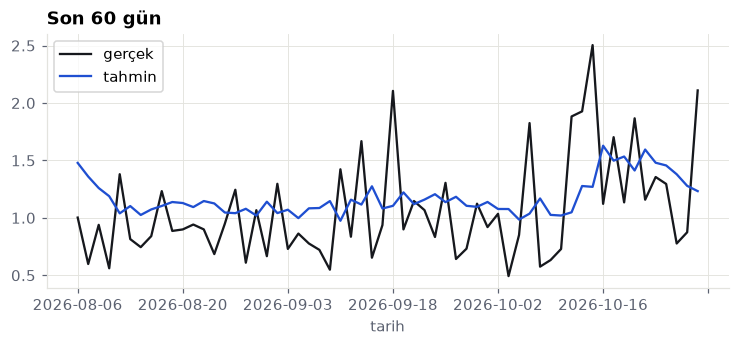

In [7]:
print('Katsayılar:', {k: round(v, 3) for k, v in M['coef'].items()})
print(f"İyileşme: %{M['improvement']:.0f}, %80 aralık isabeti: %{M['interval_hit']:.0f}")
print(f"Yarın beklenen: {M['next']['points']:.0f} puan ({M['next']['points_lo']:.0f}–{M['next']['points_hi']:.0f})")
r = pd.DataFrame(M['recent'], columns=['tarih', 'gerçek', 'tahmin']).set_index('tarih')
r.plot(figsize=(8, 3), color=[charts.INK, charts.ACC]); plt.title('Son 60 gün'); plt.show()

**Yorum:** Model yalnızca *ne kadar* hareket beklendiğini söyler, yönü söylemez. Oynaklık kümelendiği için (2. defter) dünün ve son haftanın aralığı yarını kısmen açıklar; R² düşük görünse de basit kuralları geçmesi anlamlıdır, çünkü günlük aralığın büyük kısmı habere bağlı ve öngörülemez.